# LAB 4 — PHẦN C: UNIT SELECTION & BOUNDARY SMOOTHING

**Học phần:** CSE457 — Xử lý âm thanh và tiếng nói  
**Tài liệu:** Lab 4, mục 4.3, 5.4 và thí nghiệm 1–2 mục 6.  
**Chạy trên:** VS Code (Python notebook), **không cần Internet**.

**Mục tiêu:**
1. Đọc 2 (hoặc nhiều) candidate cho mỗi word-unit từ dữ liệu bước A.
2. Tính **target cost** theo duration/RMS và **join cost** theo phổ/RMS ở vùng 25 ms cuối–đầu.
3. Áp dụng **dynamic programming (Viterbi shortest-path)** để chọn một candidate mỗi vị trí trong câu.
4. So sánh 4 mức cross-fade **0, 5, 15, 30 ms** và xuất `best_concat.wav` (mặc định 15 ms).
5. Lưu WAV, các bảng cost, biểu đồ phổ/waveform có đánh dấu biên và đối chiếu baseline bước B.

**Lưu ý khoa học:** tổng cost là chỉ số tối ưu thuật toán, không trực tiếp đồng nghĩa naturalness hay intelligibility. Để kết luận giọng hay hơn cần *nghe thực tế* và/hoặc listening test. Không sửa đè `raw_concat.wav`.

## 0. Cấu trúc thư mục và thư viện

```text
Lab04_TTS/
├── Lab04_Buoc1_A_Dataset.ipynb
├── Lab04_Buoc2_B.ipynb
├── Lab04_Buoc3_C.ipynb       ← notebook này
├── lab4_data/
│   ├── units/                  ← 32 file WAV đã xử lý, 16 kHz, mono
│   ├── metadata.csv            ← tùy chọn
│   └── source_provenance.csv   ← tùy chọn, có speaker
├── audio_output/
│   └── raw_concat.wav          ← tạo từ Bước B
└── figures/
```

Nếu đã chạy bước A/B thì thông thường không cần cài thêm. Nếu thiếu thư viện:

```powershell
python -m pip install numpy pandas matplotlib scipy soundfile ipython
```

Chạy **Run All** và kiểm tra bảng kết quả ở các cell cuối.

In [1]:
from pathlib import Path
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import stft
from IPython.display import display, Audio

SR = 16000
ROOT = Path.cwd().resolve()
UNIT_DIR = ROOT / 'lab4_data' / 'units'
DATA_DIR = ROOT / 'lab4_data'
OUT_DIR = ROOT / 'audio_output'
FIG_DIR = ROOT / 'figures'
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not UNIT_DIR.is_dir():
    raise FileNotFoundError(f'Không tìm thấy {UNIT_DIR}. Hãy mở VS Code đúng folder Lab04_TTS.')
print('Root:', ROOT)
print('WAV tìm thấy:', len(list(UNIT_DIR.glob('*.wav'))))

Root: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien
WAV tìm thấy: 32


## 1. Chuẩn hóa câu và đọc inventory

**Quy tắc của case study:** chuỗi số là **mã xếp hàng**, đọc từng chữ số: `23 → hai ba`. Mỗi candidate lưu riêng dạng `moi_01.wav`, `moi_02.wav`, ... . Dữ liệu phải giữ **nhãn có dấu** khi xử lý token.

In [2]:
UNIT_NAMES = {
    'mời':'moi', 'khách':'khach', 'hàng':'hang', 'số':'so',
    'không':'khong', 'một':'mot', 'hai':'hai', 'ba':'ba',
    'bốn':'bon', 'năm':'nam', 'sáu':'sau', 'bảy':'bay',
    'tám':'tam', 'chín':'chin', 'đến':'den', 'quầy':'quay',
}
DIGIT = {'0':'không', '1':'một', '2':'hai', '3':'ba', '4':'bốn',
         '5':'năm', '6':'sáu', '7':'bảy', '8':'tám', '9':'chín'}
TEST_SENTENCE = 'Mời khách hàng số 23 đến quầy 5.'

# Tham số có thể đổi để kiểm tra độ nhạy mô hình
JOIN_MS = 25                  # 20–30 ms theo đề
NFFT = 512
LAMBDA_JOIN = 1.0             # trọng số join so với target
SPEAKER_SWITCH_PENALTY = 0.35 # chỉ áp dụng khi biết speaker thật; chọn 0.0 để tắt
BEST_XFADE_MS = 15            # ứng viên mặc định; đánh giá nghe để quyết định cuối
CROSSFADE_VALUES = [0, 5, 15, 30]
TARGET_RMS = 0.08             # giá trị RMS được chuẩn hóa ở Bước A


def normalize_text(text):
    text = unicodedata.normalize('NFC', text).lower().replace('_', ' ')
    text = re.sub(r'[^\w\s]', ' ', text, flags=re.UNICODE)
    tokens = []
    for t in text.split():
        if t.isdecimal():
            if any(d not in DIGIT for d in t):
                raise ValueError(f'Chữ số chưa hỗ trợ: {t}')
            tokens.extend(DIGIT[d] for d in t)
        else:
            tokens.append(t)
    unknown = sorted(set(tokens) - set(UNIT_NAMES))
    if unknown:
        raise ValueError('Có từ ngoài inventory: ' + ', '.join(unknown))
    if not tokens:
        raise ValueError('Câu đầu vào rỗng')
    return tokens

TOKENS = normalize_text(TEST_SENTENCE)
print('Chuỗi token:', TOKENS)
assert TOKENS == ['mời','khách','hàng','số','hai','ba','đến','quầy','năm']
assert BEST_XFADE_MS in CROSSFADE_VALUES

Chuỗi token: ['mời', 'khách', 'hàng', 'số', 'hai', 'ba', 'đến', 'quầy', 'năm']


In [3]:
# Đọc provenance/metadata để biết người nói. Không dùng speaker tự suy đoán từ âm thanh.
speaker_lookup = {}
for name in ['source_provenance.csv', 'metadata.csv']:
    path = DATA_DIR / name
    if not path.exists():
        continue
    meta = pd.read_csv(path, encoding='utf-8-sig')
    filecol = next((k for k in ['filename','file_path','path'] if k in meta.columns), None)
    if filecol and 'speaker' in meta.columns:
        for row in meta[[filecol, 'speaker']].itertuples(index=False, name=None):
            filename, speaker = row
            if pd.notna(filename) and pd.notna(speaker) and str(speaker).strip():
                filename = Path(str(filename).replace('\\','/')).name
                speaker_lookup[filename] = str(speaker)

def rms(x):
    arr = np.asarray(x, dtype=np.float64)
    return float(np.sqrt(np.mean(arr*arr) + 1e-12)) if len(arr) else 0.0

inventory = {}
rows = []
for word, slug in UNIT_NAMES.items():
    paths = sorted(UNIT_DIR.glob(f'{slug}_*.wav'))
    inventory[word] = []
    for path in paths:
        info = sf.info(path)
        if info.samplerate != SR or info.channels != 1 or info.subtype != 'PCM_16':
            raise ValueError(f'{path.name} phải là mono / {SR} Hz / PCM_16; nhận {info}')
        x, sr = sf.read(path, dtype='float32')
        if len(x) < round(0.1 * SR) or not np.isfinite(x).all():
            raise ValueError(f'Unit hỏng hoặc quá ngắn: {path}')
        unit = {'word':word, 'filename':path.name, 'speaker':speaker_lookup.get(path.name,'unknown'),
                'x':x, 'duration_s':len(x)/SR, 'rms':rms(x)}
        inventory[word].append(unit)
        rows.append({k:unit[k] for k in ('word','filename','speaker','duration_s','rms')})

inventory_stats = pd.DataFrame(rows)
missing = [w for w in TOKENS if not inventory[w]]
if missing:
    raise FileNotFoundError(f'Thiếu WAV cho các từ: {sorted(set(missing))}. Chạy Bước A trước.')
if any(len(inventory[w]) < 2 for w in set(TOKENS)):
    print('CẢNH BÁO: có từ trong câu test chỉ có một candidate; DP vẫn chạy nhưng ít phương án.')
print('Số file inventory:', len(inventory_stats), ' | Candidate cho 9 vị trí:',
      [len(inventory[w]) for w in TOKENS])
display(inventory_stats)

Số file inventory: 32  | Candidate cho 9 vị trí: [2, 2, 2, 2, 2, 2, 2, 2, 2]


,word,filename,speaker,duration_s,rms
0,mời,moi_01.wav,lephuong,0.500000,0.080000
1,mời,moi_02.wav,longtran,0.750000,0.080000
2,khách,khach_01.wav,lephuong,0.625000,0.080000
3,khách,khach_02.wav,longtran,0.750000,0.077255
4,hàng,hang_01.wav,lephuong,0.500000,0.080000
5,hàng,hang_02.wav,longtran,0.625000,0.080000
6,số,so_01.wav,lephuong,0.625000,0.080000
7,số,so_02.wav,longtran,0.625000,0.080000
8,không,khong_01.wav,lephuong,0.625000,0.080000
9,không,khong_02.wav,longtran,0.625000,0.080000


## 2. Định nghĩa target cost và join cost

Dùng **target cost** cho mỗi candidate: khoảng cách duration tới trung vị duration của các candidate cùng từ, và khoảng cách RMS tới mức 0,08. Đây là *proxy* cho prosody mục tiêu; không phải mô hình ngữ điệu đã huấn luyện.

\[
C_{target}(u,w)=0.7\left(\frac{d_u-\widetilde d_w}{\max(0.15,0.25\widetilde d_w)}\right)^2+
0.3\left(\frac{RMS_u-0.08}{0.03}\right)^2
\]

Với hai unit liên tiếp, ta lấy **25 ms cuối** của unit trước và **25 ms đầu** của unit sau (cửa sổ Hann), tính sai lệch log-magnitude spectrum:

\[
D_{spec}(a,b)=\frac{1}{K}\sum_{k=1}^K(L_a[k]-L_b[k])^2
\]

Để kết hợp nhiều thước đo khác thang, chuẩn hóa spectral mismatch bằng trung vị của các cặp trong câu; cộng penalty nhỏ từ chênh RMS cục bộ và (nếu có speaker ID đáng tin) từ việc đổi speaker. Các trọng số đều minh bạch và có thể thử nghiệm thay đổi.

**Lưu ý:** có silence ở biên → join cost có thể phản ánh silence thay vì chất lượng ngữ âm. Vì vậy cần đối chiếu waveform/spectrogram và nghe, không coi cost là điểm MOS.

In [4]:
def target_cost(u):
    ds = [v['duration_s'] for v in inventory[u['word']]]
    target_d = float(np.median(ds))
    d_scale = max(0.15, 0.25 * target_d)
    return float(0.7*((u['duration_s']-target_d)/d_scale)**2 +
                 0.3*((u['rms']-TARGET_RMS)/0.03)**2)


def log_spectrum(part, nfft=NFFT):
    win = np.hanning(len(part))
    return 20*np.log10(np.maximum(np.abs(np.fft.rfft(part*win, n=nfft)), 1e-8))


def join_features(a, b, ms=JOIN_MS):
    n = round(SR * ms/1000)
    if len(a['x']) < n or len(b['x']) < n:
        raise ValueError('Unit ngắn hơn vùng phân tích 25ms')
    left = a['x'][-n:]
    right = b['x'][:n]
    mse_db2 = float(np.mean((log_spectrum(left)-log_spectrum(right))**2))
    gap_db = float(20*np.log10((rms(right)+1e-9)/(rms(left)+1e-9)))
    speaker_known = a['speaker'] != 'unknown' and b['speaker'] != 'unknown'
    switch = int(speaker_known and a['speaker'] != b['speaker'])
    return mse_db2, gap_db, switch

# Chuẩn hóa phổ theo thang đo của đúng câu test; độc lập với đường chọn DP.
all_spectral = []
for wa, wb in zip(TOKENS[:-1], TOKENS[1:]):
    for a in inventory[wa]:
        for b in inventory[wb]:
            all_spectral.append(join_features(a,b)[0])
SPECTRAL_SCALE = max(float(np.median(all_spectral)), 1e-6)
print('Spectral scale (median, dB²):', round(SPECTRAL_SCALE, 3))


def join_cost(a,b):
    spec, gap_db, change_speaker = join_features(a,b)
    spec_normalized = spec / SPECTRAL_SCALE
    rms_component = 0.2 * (gap_db / 12.0)**2
    speaker_component = SPEAKER_SWITCH_PENALTY * change_speaker
    return float(spec_normalized + rms_component + speaker_component)


def path_cost(units):
    target_total = sum(target_cost(u) for u in units)
    join_total = sum(join_cost(a,b) for a,b in zip(units[:-1],units[1:]))
    total = target_total + LAMBDA_JOIN * join_total
    return dict(target_cost=float(target_total), join_cost=float(join_total), total_cost=float(total))

Spectral scale (median, dB²): 95.979


## 3. Dynamic programming — chọn chuỗi candidate có tổng cost nhỏ nhất

Ở vị trí `j`, mỗi candidate là một đỉnh; `C_target` là chi phí đỉnh, `C_join` là chi phí nối hai đỉnh kế tiếp. Với chuỗi 9 từ và 2 candidate/từ có tối đa \(2^9=512\) cách lựa chọn; DP tránh phải liệt kê hết khi inventory lớn.

\[
DP[j,k]=C_{target}(u_{jk})+\min_i\big(DP[j-1,i]+\lambda C_{join}(u_{j-1,i},u_{jk})\big).
\]

In [5]:
def select_dp(tokens):
    layers = [inventory[word] for word in tokens]
    dp = [[target_cost(u) for u in layers[0]]]
    back = [[-1] * len(layers[0])]
    for j in range(1, len(layers)):
        costs, parents = [], []
        for candidate in layers[j]:
            options = [dp[j-1][i] + LAMBDA_JOIN*join_cost(prev, candidate)
                       for i, prev in enumerate(layers[j-1])]
            winner = int(np.argmin(options))
            costs.append(target_cost(candidate)+options[winner])
            parents.append(winner)
        dp.append(costs)
        back.append(parents)
    last = int(np.argmin(dp[-1]))
    idx = [last]
    for j in range(len(layers)-1, 0, -1):
        idx.append(back[j][idx[-1]])
    idx.reverse()
    best = [layers[j][k] for j,k in enumerate(idx)]
    assert np.isclose(path_cost(best)['total_cost'], min(dp[-1]), atol=1e-8)
    return best


def select_baseline(tokens):
    chosen = []
    for token in tokens:
        preferred_name = f"{UNIT_NAMES[token]}_01.wav"
        cand = next((u for u in inventory[token] if u['filename']==preferred_name), None)
        if cand is None:
            raise FileNotFoundError(f'Không thấy {preferred_name} để so sánh đúng baseline Bước B')
        chosen.append(cand)
    return chosen

baseline_units = select_baseline(TOKENS)
best_units = select_dp(TOKENS)
base_cost = path_cost(baseline_units)
best_cost = path_cost(best_units)
assert best_cost['total_cost'] <= base_cost['total_cost'] + 1e-8

selection = pd.DataFrame([{
    'position': j+1, 'word': token, 'baseline':u0['filename'], 'best':u1['filename'],
    'baseline_speaker':u0['speaker'], 'best_speaker':u1['speaker'],
    'baseline_duration_s':u0['duration_s'], 'best_duration_s':u1['duration_s'],
    'target_cost_selected':target_cost(u1), 'changed':u0['filename']!=u1['filename']
} for j,(token,u0,u1) in enumerate(zip(TOKENS,baseline_units,best_units))])
selection.to_csv(OUT_DIR/'c_selected_units.csv', index=False, encoding='utf-8-sig')
display(selection)
print('Số vị trí đổi candidate:', int(selection.changed.sum()))
print('Baseline cost:', {k:round(v,4) for k,v in base_cost.items()})
print('Selected cost:', {k:round(v,4) for k,v in best_cost.items()})

,position,word,baseline,best,baseline_speaker,best_speaker,baseline_duration_s,best_duration_s,target_cost_selected,changed
0,1,mời,moi_01.wav,moi_01.wav,lephuong,lephuong,0.500,0.500,4.480000e-01,False
1,2,khách,khach_01.wav,khach_01.wav,lephuong,lephuong,0.625,0.625,9.256198e-02,False
2,3,hàng,hang_01.wav,hang_01.wav,lephuong,lephuong,0.500,0.500,1.215278e-01,False
3,4,số,so_01.wav,so_01.wav,lephuong,lephuong,0.625,0.625,2.207628e-12,False
4,5,hai,hai_01.wav,hai_01.wav,lephuong,lephuong,0.500,0.500,3.533934e-01,False
5,6,ba,ba_01.wav,ba_01.wav,lephuong,lephuong,0.500,0.500,2.213306e+00,False
6,7,đến,den_01.wav,den_01.wav,lephuong,lephuong,0.625,0.625,9.256198e-02,False
7,8,quầy,quay_01.wav,quay_01.wav,lephuong,lephuong,0.500,0.500,1.157644e-01,False
8,9,năm,nam_01.wav,nam_01.wav,lephuong,lephuong,0.625,0.625,1.680864e-12,False


Số vị trí đổi candidate: 0
Baseline cost: {'target_cost': 3.4371, 'join_cost': 7.7651, 'total_cost': 11.2022}
Selected cost: {'target_cost': 3.4371, 'join_cost': 7.7651, 'total_cost': 11.2022}


,path,target_cost,join_cost,total_cost
0,baseline_01,3.4371,7.7651,11.2022
1,unit_selection_DP,3.4371,7.7651,11.2022


,boundary_id,word_pair,baseline_files,best_files,join_cost_baseline,join_cost_best,spectral_db2_baseline,spectral_db2_best,rms_gap_db_baseline,rms_gap_db_best,speaker_change_baseline,speaker_change_best
0,1,mời → khách,moi_01.wav + khach_01.wav,moi_01.wav + khach_01.wav,1.139,1.139,97.182,97.182,-9.534,-9.534,0,0
1,2,khách → hàng,khach_01.wav + hang_01.wav,khach_01.wav + hang_01.wav,0.613,0.613,58.862,58.862,0.098,0.098,0,0
2,3,hàng → số,hang_01.wav + so_01.wav,hang_01.wav + so_01.wav,1.154,1.154,90.621,90.621,-12.299,-12.299,0,0
3,4,số → hai,so_01.wav + hai_01.wav,so_01.wav + hai_01.wav,0.806,0.806,75.908,75.908,-3.254,-3.254,0,0
4,5,hai → ba,hai_01.wav + ba_01.wav,hai_01.wav + ba_01.wav,1.275,1.275,103.052,103.052,-12.027,-12.027,0,0
5,6,ba → đến,ba_01.wav + den_01.wav,ba_01.wav + den_01.wav,1.133,1.133,108.767,108.767,-0.237,-0.237,0,0
6,7,đến → quầy,den_01.wav + quay_01.wav,den_01.wav + quay_01.wav,0.697,0.697,64.020,64.020,4.615,4.615,0,0
7,8,quầy → năm,quay_01.wav + nam_01.wav,quay_01.wav + nam_01.wav,0.949,0.949,80.319,80.319,-8.972,-8.972,0,0


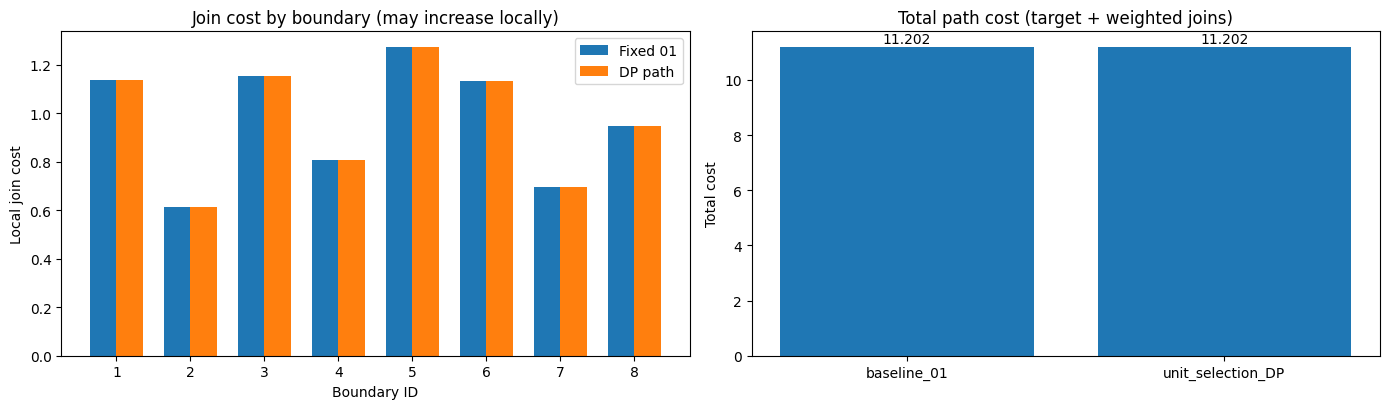

In [6]:
summary_cost = pd.DataFrame([
    {'path':'baseline_01', **base_cost},
    {'path':'unit_selection_DP', **best_cost},
])
summary_cost.to_csv(OUT_DIR/'c_total_cost_comparison.csv', index=False, encoding='utf-8-sig')

join_table = []
for j in range(1,len(TOKENS)):
    a0,b0 = baseline_units[j-1],baseline_units[j]
    a1,b1 = best_units[j-1],best_units[j]
    spec0,gap0,switch0 = join_features(a0,b0)
    spec1,gap1,switch1 = join_features(a1,b1)
    join_table.append({
        'boundary_id':j, 'word_pair':TOKENS[j-1]+' → '+TOKENS[j],
        'baseline_files':a0['filename']+' + '+b0['filename'],
        'best_files':a1['filename']+' + '+b1['filename'],
        'join_cost_baseline':join_cost(a0,b0), 'join_cost_best':join_cost(a1,b1),
        'spectral_db2_baseline':spec0, 'spectral_db2_best':spec1,
        'rms_gap_db_baseline':gap0, 'rms_gap_db_best':gap1,
        'speaker_change_baseline':switch0, 'speaker_change_best':switch1,
    })
join_df = pd.DataFrame(join_table)
join_df.to_csv(OUT_DIR/'c_join_cost_by_boundary.csv', index=False, encoding='utf-8-sig')
display(summary_cost.round(4))
display(join_df.round(3))

fig, axes = plt.subplots(1,2, figsize=(14,4.2))
xs = np.arange(len(join_df))
w = 0.36
axes[0].bar(xs-w/2, join_df.join_cost_baseline, width=w, label='Fixed 01')
axes[0].bar(xs+w/2, join_df.join_cost_best, width=w, label='DP path')
axes[0].set_xticks(xs, join_df.boundary_id.astype(str))
axes[0].set_xlabel('Boundary ID'); axes[0].set_ylabel('Local join cost')
axes[0].set_title('Join cost by boundary (may increase locally)'); axes[0].legend()
axes[1].bar(summary_cost.path, summary_cost.total_cost)
axes[1].set_title('Total path cost (target + weighted joins)')
axes[1].set_ylabel('Total cost')
for i,v in enumerate(summary_cost.total_cost):
    axes[1].annotate(f'{v:.3f}', (i,v), ha='center', xytext=(0,3), textcoords='offset points')
plt.tight_layout()
plt.savefig(FIG_DIR/'c_unit_selection_costs.png', dpi=170)
plt.show()

## 4. Tạo WAV với cross-fade 0 / 5 / 15 / 30 ms

Công thức tại vùng overlap N mẫu:

\[
y[n]=(1-\alpha[n])x_1[n]+\alpha[n]x_2[n],\quad \alpha[n]=n/(N-1),\quad 0\leq n<N.
\]

Để tránh lỗi **ghép nhiều lần làm sai thời điểm biên**, sau mỗi lần ghép ta lưu tâm vùng overlap (một ranh giới chuyển tiếp mang tính quy ước). Thời lượng giảm đi `N/SR` ở mỗi biên.

**Điểm cần nhớ:** cross-fade có thể giảm click nhưng nếu overlap quá dài, những âm vị đầu/cuối từ sẽ bị trộn và mờ phụ âm. Hãy nghe các WAV, không chỉ nhìn đồ thị.

In [7]:
def crossfade(a, b, n):
    n = max(0, min(int(n),len(a),len(b)))
    if n == 0:
        return np.concatenate([a,b]).astype(np.float32)
    alpha = np.linspace(0,1,n,endpoint=True,dtype=np.float64)
    merged = (1-alpha)*a[-n:].astype(np.float64) + alpha*b[:n].astype(np.float64)
    return np.concatenate([a[:-n], merged, b[n:]]).astype(np.float32)


def concat_units(units, fade_ms=0):
    if not units:
        raise ValueError('Không có unit')
    fade_n = round(SR * fade_ms / 1000)
    y = units[0]['x'].copy()
    boundaries = []
    for j,u in enumerate(units[1:],start=1):
        n = min(fade_n,len(y),len(u['x']))
        # Với cross-fade, ranh giới là trung điểm vùng overlap (không còn điểm cắt vật lý)
        mid_sample = len(y)-n//2
        boundaries.append({'boundary_id':j, 'word_pair':units[j-1]['word']+' → '+u['word'],
                           'sample_index':mid_sample, 'time_s':mid_sample/SR, 'fade_ms':fade_ms})
        y = crossfade(y, u['x'], n)
    return y, pd.DataFrame(boundaries)

raw_reconstructed, raw_boundaries = concat_units(baseline_units, 0)
raw_file = OUT_DIR/'raw_concat.wav'
if raw_file.exists():
    old, old_sr = sf.read(raw_file, dtype='float32')
    if old_sr != SR or len(old)!=len(raw_reconstructed) or not np.allclose(old,raw_reconstructed,atol=5e-5):
        raise ValueError('raw_concat.wav khác baseline `_01` hiện tại. Hãy chạy lại Bước B trên chính inventory đang sử dụng.')
    print('Đối chiếu baseline bước B: KHỚP.')
else:
    print('Chưa có raw_concat.wav; tạo lại bản fixed candidate 01 (không cross-fade).')
    sf.write(raw_file, raw_reconstructed, SR, subtype='PCM_16')

outputs = {}
for ms in CROSSFADE_VALUES:
    y, bb = concat_units(best_units, ms)
    fn = OUT_DIR/f'c_selected_xfade_{ms:02d}ms.wav'
    sf.write(fn,y,SR,subtype='PCM_16')
    bb.to_csv(OUT_DIR/f'c_boundaries_{ms:02d}ms.csv',index=False,encoding='utf-8-sig')
    outputs[ms] = {'audio':y, 'boundary':bb, 'path':fn}
    print(f'{ms:>2} ms: {fn.name} | duration {len(y)/SR:.3f}s | peak {np.max(np.abs(y)):.3f}')

best_wave = outputs[BEST_XFADE_MS]['audio']
best_output = OUT_DIR/'best_concat.wav'
sf.write(best_output,best_wave,SR,subtype='PCM_16')
print('Đã lưu best_concat.wav từ cấu hình:', BEST_XFADE_MS,'ms')
assert len(outputs[0]['audio']) == sum(len(u['x']) for u in best_units)
assert len(outputs[15]['audio']) == len(outputs[0]['audio'])- (len(TOKENS)-1)*round(15*SR/1000)

print('\nAUDIO BASELINE (B):')
display(Audio(filename=str(raw_file)))
print('AUDIO CHỌN UNIT (không xfade):')
display(Audio(filename=str(outputs[0]['path'])))
print(f'AUDIO ĐÃ XFADE {BEST_XFADE_MS} ms:')
display(Audio(filename=str(best_output)))

Đối chiếu baseline bước B: KHỚP.
 0 ms: c_selected_xfade_00ms.wav | duration 5.000s | peak 0.633
 5 ms: c_selected_xfade_05ms.wav | duration 4.960s | peak 0.633
15 ms: c_selected_xfade_15ms.wav | duration 4.880s | peak 0.633
30 ms: c_selected_xfade_30ms.wav | duration 4.760s | peak 0.633
Đã lưu best_concat.wav từ cấu hình: 15 ms

AUDIO BASELINE (B):


AUDIO CHỌN UNIT (không xfade):


AUDIO ĐÃ XFADE 15 ms:


## 5. Đo và vẽ mức khác biệt tại biên

Bảng ở đây dùng `abs_sample_jump`, RMS gap và spectral mismatch trong cửa sổ 25 ms quanh **tâm chuyển tiếp**. Với cross-fade >0, tâm không còn là điểm cắt cứng: **không thể coi các chỉ số này là phép đo perceptual click hoàn chỉnh**. Cách tốt nhất là vừa đối chiếu đồ thị vừa nghe hai biên đáng chú ý (`mời → khách`, `hàng → số`).

In [8]:
def boundary_metrics(y, boundary):
    k = int(boundary)
    n = round(SR*JOIN_MS/1000)
    if k < n or k+n > len(y):
        raise ValueError('Biên gần đầu/cuối quá để đo 25 ms')
    left, right = y[k-n:k], y[k:k+n]
    jump = float(abs(y[k]-y[k-1]))
    return {'abs_sample_jump':jump,
            'rms_gap_db':float(20*np.log10((rms(right)+1e-9)/(rms(left)+1e-9))),
            'spectral_mismatch_db2':float(np.mean((log_spectrum(left)-log_spectrum(right))**2))}

metric_rows = []
for name,y,bb in [('baseline_B',raw_reconstructed,raw_boundaries)] + [
        (f'DP_xfade_{ms:02d}ms', outputs[ms]['audio'],outputs[ms]['boundary']) for ms in CROSSFADE_VALUES]:
    for boundary in bb.itertuples(index=False):
        m = boundary_metrics(y,boundary.sample_index)
        metric_rows.append({'variant':name, 'fade_ms':boundary.fade_ms,
                            'boundary_id':boundary.boundary_id,'word_pair':boundary.word_pair,
                            'time_s':boundary.time_s, **m})
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(OUT_DIR/'c_boundary_metrics.csv',index=False,encoding='utf-8-sig')
metrics_summary = metrics.groupby('variant',sort=False).agg(
    mean_abs_sample_jump=('abs_sample_jump','mean'),
    max_abs_sample_jump=('abs_sample_jump','max'),
    mean_abs_rms_gap_db=('rms_gap_db',lambda s:float(np.mean(np.abs(s)))),
    mean_spectral_db2=('spectral_mismatch_db2','mean')
).reset_index()
metrics_summary.to_csv(OUT_DIR/'c_boundary_metrics_summary.csv',index=False,encoding='utf-8-sig')
display(metrics_summary.round(4))

# So sánh độ dài / RMS / clip. Các chỉ số mang tính mô tả chứ KHÔNG phải MOS.
quality = []
for name,y in [('baseline_B',raw_reconstructed)] + [
        (f'DP_xfade_{ms:02d}ms',outputs[ms]['audio']) for ms in CROSSFADE_VALUES]:
    quality.append({'variant':name,'duration_s':len(y)/SR,'rms':rms(y),
                    'peak':float(np.max(np.abs(y))), 'clipped_fraction':float(np.mean(np.abs(y)>=0.999))})
quality_df = pd.DataFrame(quality)
quality_df.to_csv(OUT_DIR/'c_audio_summary.csv',index=False,encoding='utf-8-sig')
display(quality_df.round(5))

,variant,mean_abs_sample_jump,max_abs_sample_jump,mean_abs_rms_gap_db,mean_spectral_db2
0,baseline_B,0.0205,0.0515,6.3794,84.8414
1,DP_xfade_00ms,0.0205,0.0515,6.3794,84.8414
2,DP_xfade_05ms,0.0011,0.0021,6.3813,85.7486
3,DP_xfade_15ms,0.0012,0.0017,7.0865,98.6838
4,DP_xfade_30ms,0.0014,0.0027,7.1897,103.3646


,variant,duration_s,rms,peak,clipped_fraction
0,baseline_B,5.00,0.08000,0.63309,0.0
1,DP_xfade_00ms,5.00,0.08000,0.63309,0.0
2,DP_xfade_05ms,4.96,0.08030,0.63309,0.0
3,DP_xfade_15ms,4.88,0.08090,0.63309,0.0
4,DP_xfade_30ms,4.76,0.08181,0.63309,0.0


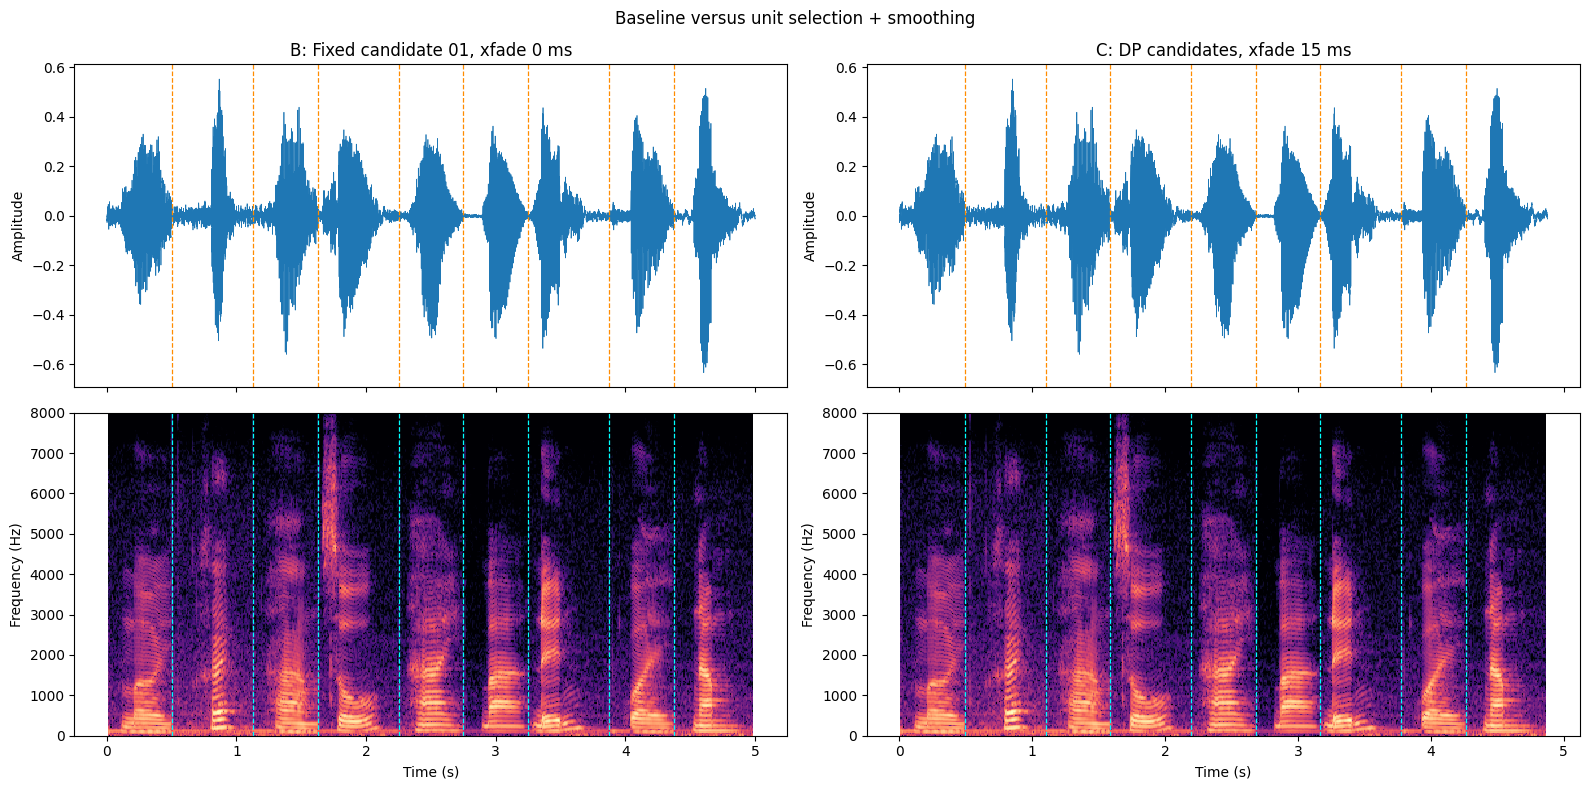

In [9]:
def draw_stft(ax,y,sr=SR):
    nperseg=400
    f,t,z=stft(y, fs=sr, window='hann',nperseg=nperseg,noverlap=240,
               nfft=512,boundary=None,padded=False)
    db=20*np.log10(np.maximum(np.abs(z),1e-8))
    pcm = ax.pcolormesh(t,f,db,shading='auto',cmap='magma',vmin=-90,vmax=-20)
    ax.set_ylim(0,8000)
    return pcm

fig, axes = plt.subplots(2,2,figsize=(16,8),sharex='col')
for col,(title,y,bb) in enumerate([
    ('B: Fixed candidate 01, xfade 0 ms',raw_reconstructed,raw_boundaries),
    (f'C: DP candidates, xfade {BEST_XFADE_MS} ms',best_wave,outputs[BEST_XFADE_MS]['boundary'])
]):
    t=np.arange(len(y))/SR
    axes[0,col].plot(t,y,lw=0.5)
    axes[0,col].set_title(title)
    axes[0,col].set_ylabel('Amplitude')
    pcm=draw_stft(axes[1,col],y)
    for bound in bb.itertuples(index=False):
        axes[0,col].axvline(bound.time_s,color='darkorange',ls='--',lw=0.9)
        axes[1,col].axvline(bound.time_s,color='cyan',ls='--',lw=0.9)
    axes[1,col].set_ylabel('Frequency (Hz)')
    axes[1,col].set_xlabel('Time (s)')
fig.suptitle('Baseline versus unit selection + smoothing')
fig.tight_layout()
fig.savefig(FIG_DIR/'c_before_after_waveform_spectrogram.png',dpi=165)
plt.show()

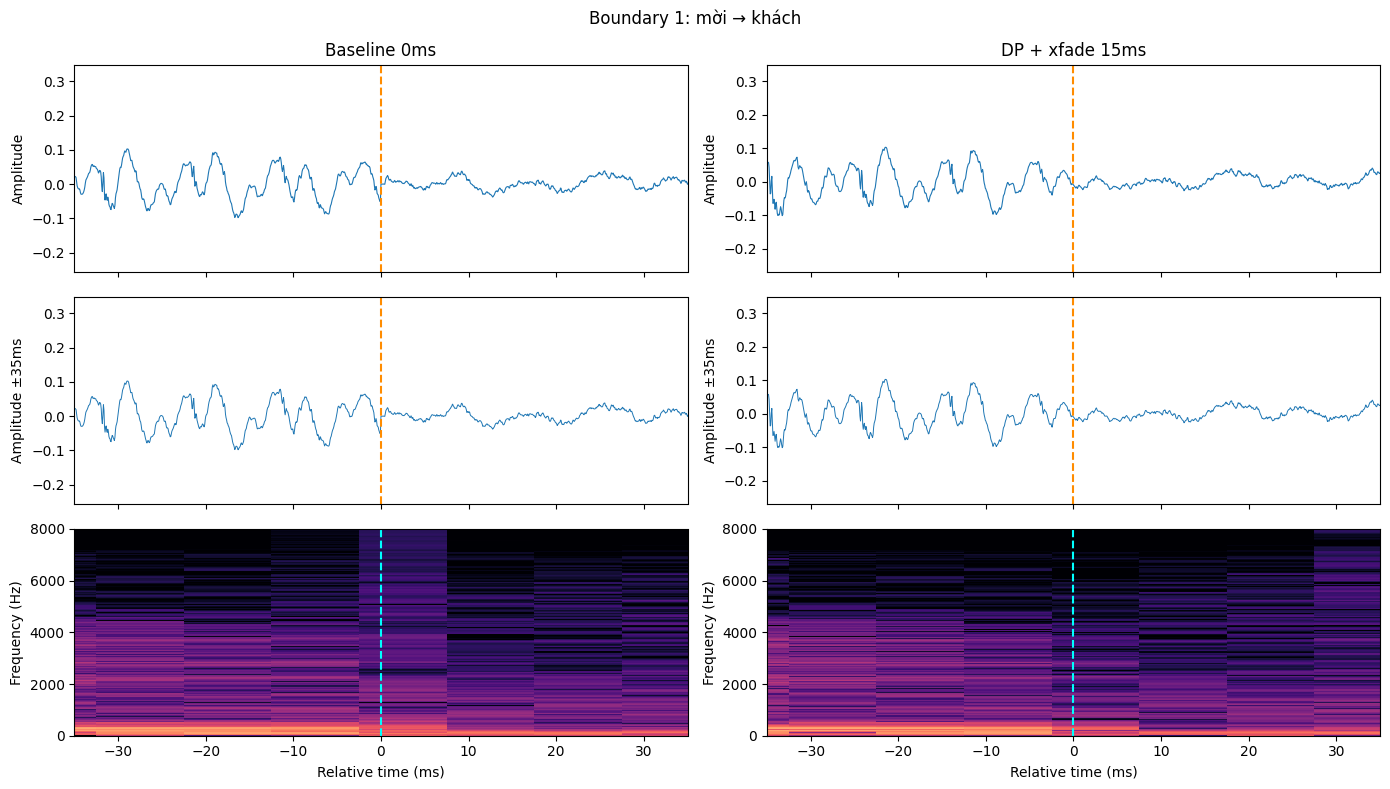

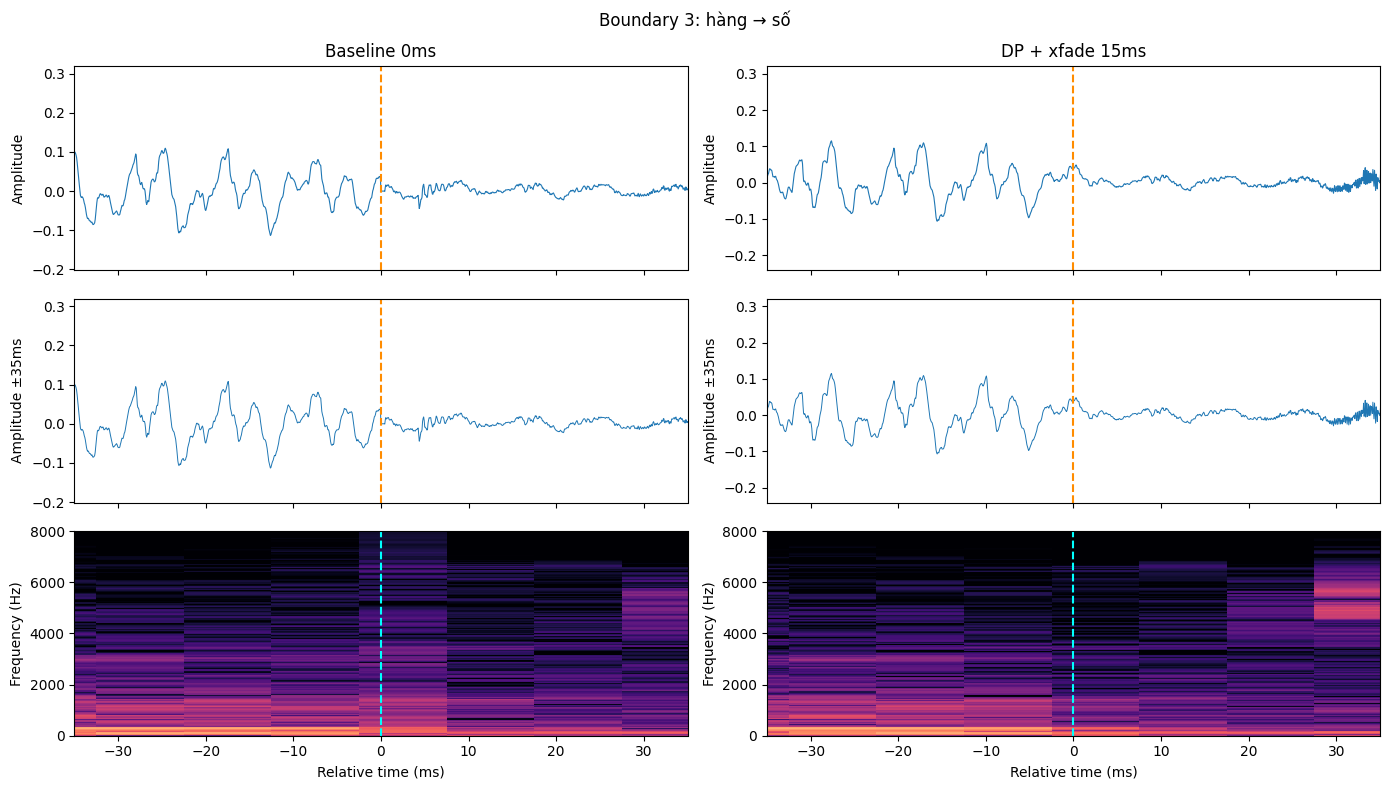

In [10]:
# Phóng to hai biên cụ thể có độ nhảy mẫu lớn ở bản B.
BOUNDARIES_TO_COMPARE = [1,3]   # 1: mời→khách; 3: hàng→số

for bid in BOUNDARIES_TO_COMPARE:
    fig,axes=plt.subplots(3,2,figsize=(14,8),sharex='col')
    for ci, (caption,y,bb) in enumerate([
        ('Baseline 0ms',raw_reconstructed,raw_boundaries),
        (f'DP + xfade {BEST_XFADE_MS}ms',best_wave,outputs[BEST_XFADE_MS]['boundary'])
    ]):
        k=int(bb.loc[bb.boundary_id==bid,'sample_index'].iloc[0])
        half=round(0.12*SR)
        start=max(0,k-half);end=min(len(y),k+half)
        clip=y[start:end]
        x=(np.arange(start,end)-k)/SR*1000
        axes[0,ci].plot(x,clip,lw=0.8)
        axes[0,ci].axvline(0,color='darkorange',ls='--')
        axes[0,ci].set_title(caption)
        axes[0,ci].set_ylabel('Amplitude')
        axes[1,ci].plot(x,clip,lw=0.7)
        axes[1,ci].set_xlim(-35,35)
        axes[1,ci].axvline(0,color='darkorange',ls='--')
        axes[1,ci].set_ylabel('Amplitude ±35ms')
        f,t,z=stft(clip,fs=SR,window='hann',nperseg=400,noverlap=240,nfft=512,boundary=None,padded=False)
        db=20*np.log10(np.maximum(np.abs(z),1e-8))
        tt=(t + start/SR - k/SR)*1000
        axes[2,ci].pcolormesh(tt,f,db,shading='auto',cmap='magma',vmin=-90,vmax=-20)
        axes[2,ci].axvline(0,color='cyan',ls='--')
        axes[2,ci].set_ylim(0,8000)
        axes[2,ci].set_ylabel('Frequency (Hz)')
        axes[2,ci].set_xlabel('Relative time (ms)')
    fig.suptitle(f'Boundary {bid}: {TOKENS[bid-1]} → {TOKENS[bid]}')
    fig.tight_layout()
    fig.savefig(FIG_DIR/f'c_boundary_{bid:02d}_before_after.png',dpi=170)
    plt.show()

## 6. Nghe so sánh cross-fade và ghi phiếu thí nghiệm

Đề yêu cầu **thử 0 / 5 / 15 / 30 ms**. Mỗi mức cần kiểm tra: (i) click/đứt quãng, (ii) độ rõ phụ âm, (iii) tiếng nói bị chồng hoặc méo, (iv) độ tự nhiên. Không tự điền điểm nghe khi chưa nghe.

In [11]:
for ms in CROSSFADE_VALUES:
    print(f'===== Unit selection DP + cross-fade {ms} ms =====')
    display(Audio(filename=str(outputs[ms]['path'])))

rating_path = OUT_DIR / 'c_listening_form.csv'
if not rating_path.exists():
    pd.DataFrame([{
        'fade_ms':ms, 'click_score_1to5':'', 'consonant_clarity_1to5':'',
        'naturalness_1to5':'', 'notes':''} for ms in CROSSFADE_VALUES
    ]).to_csv(rating_path,index=False,encoding='utf-8-sig')
print('Phiếu nghe để điền thủ công:',rating_path)

===== Unit selection DP + cross-fade 0 ms =====


===== Unit selection DP + cross-fade 5 ms =====


===== Unit selection DP + cross-fade 15 ms =====


===== Unit selection DP + cross-fade 30 ms =====


Phiếu nghe để điền thủ công: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\audio_output\c_listening_form.csv


## 7. (Tùy chọn) Lặp lại với 3 câu kiểm thử theo hướng chuẩn bị cho mục G

Notebook không tự đánh giá MOS. Cell này tạo bản ghép DP + cross-fade theo cùng 3 câu đã dùng ở Bước B để chuẩn bị đánh giá ba backend sau này. **Lưu ý:** `SPECTRAL_SCALE` ở đây được xác định từ câu số 1; nếu nghiên cứu rộng hơn, nên cố định giá trị tham chiếu trên một tập phát triển độc lập.

In [12]:
TEST_SENTENCES = [
    TEST_SENTENCE,
    'Mời khách hàng số 17 đến quầy 2.',
    'Mời khách hàng số 90 đến quầy 8.',
]
extra_rows=[]
for i,sentence in enumerate(TEST_SENTENCES,1):
    tt=normalize_text(sentence)
    bb=select_dp(tt)
    yy,_=concat_units(bb,BEST_XFADE_MS)
    path=OUT_DIR/f'c_best_test_{i:02d}.wav'
    sf.write(path,yy,SR,subtype='PCM_16')
    extra_rows.append({'test_id':i,'text':sentence,'tokens':' '.join(tt),
                       'selected_files':' '.join(u['filename'] for u in bb),
                       'duration_s':len(yy)/SR,'total_cost':path_cost(bb)['total_cost'],'path':str(path)})
extra_df=pd.DataFrame(extra_rows)
extra_df.to_csv(OUT_DIR/'c_test_sentences.csv',index=False,encoding='utf-8-sig')
display(extra_df)

,test_id,text,tokens,selected_files,duration_s,total_cost,path
0,1,Mời khách hàng số 23 đến quầy 5.,mời khách hàng số hai ba đến quầy năm,moi_01.wav khach_01.wav hang_01.wav so_01.wav ...,4.880,11.202198,C:\xulyamthanh\lab04_2351260688_NguyenNgocTien...
1,2,Mời khách hàng số 17 đến quầy 2.,mời khách hàng số một bảy đến quầy hai,moi_01.wav khach_01.wav hang_01.wav so_01.wav ...,5.130,8.400452,C:\xulyamthanh\lab04_2351260688_NguyenNgocTien...
2,3,Mời khách hàng số 90 đến quầy 8.,mời khách hàng số chín không đến quầy tám,moi_01.wav khach_01.wav hang_01.wav so_01.wav ...,5.252,7.722632,C:\xulyamthanh\lab04_2351260688_NguyenNgocTien...


## 8. Những gì cần gửi để phân tích và báo cáo Lab 4C

### File bắt buộc / quan trọng
- `audio_output/best_concat.wav` — bản chọn candidate bằng DP + cross-fade đang chọn.
- `audio_output/c_selected_xfade_00ms.wav`, `_05ms.wav`, `_15ms.wav`, `_30ms.wav` — 4 thí nghiệm smoothing.
- `audio_output/c_total_cost_comparison.csv`, `c_join_cost_by_boundary.csv`, `c_selected_units.csv` — số liệu lựa chọn candidate.
- `figures/c_unit_selection_costs.png` — so sánh chi phí.
- `figures/c_before_after_waveform_spectrogram.png`, `c_boundary_01_before_after.png`, `c_boundary_03_before_after.png` — minh chứng trước/sau.
- `audio_output/c_boundary_metrics_summary.csv` — các proxy của chuyển tiếp.
- Điền `audio_output/c_listening_form.csv` **sau khi nghe thực tế**.

### Câu hỏi báo cáo
1. DP có đổi candidate nào? Tổng cost thay đổi ra sao? Tại sao **một join cost cục bộ có thể tăng** dù tổng cost giảm?
2. Trong bốn giá trị cross-fade 0, 5, 15, 30 ms, mức nào giảm click mà vẫn giữ rõ phụ âm? Kết luận phải dựa vào audio/biểu đồ.
3. Những hạn chế của target cost chỉ gồm duration/RMS; của join cost đo tại 25 ms biên, đặc biệt khi có silence và chuyển người nói.
4. Vì sao chọn waveform có sẵn khác với HMM generation (mục E)?

**Quan trọng:** `best_concat.wav` là tên theo rubric của Lab; không có nghĩa đã chứng minh nó luôn là audio nghe hay nhất. Nếu kết quả nghe tốt hơn ở 5 ms hoặc 30 ms, đổi `BEST_XFADE_MS` rồi chạy lại.